# Sesi 2 — 02. Eksplorasi Data Trafik Seluler

**Workshop Deep Learning untuk Mahasiswa Teknik Telekomunikasi — ITERA**

Sebelum membuat model, kita **kenali datanya dulu**. Data: aktivitas internet, telepon, dan SMS per jam di satu kotak 235 m × 235 m sekitar Duomo, Milan, selama 8 minggu (4 Nov – 29 Des 2013). Sumber: *Telecom Italia Big Data Challenge* (Barlacchi dkk., 2015).

| Bagian | Isi |
|---|---|
| 1 | Melihat 8 minggu data & pembagian *train / val / test* |
| 2 | Pola harian & mingguan |
| 3 | Hubungan internet, telepon, SMS |
| 4 | Autokorelasi: "seberapa mirip trafik sekarang dengan *k* jam lalu?" |
| 5 | Minggu Natal: ketika pola berubah |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Palet warna ITERA (sama dengan slide)
NAVY, GOLD, RED, TEAL, GREEN, GRAY = "#0B1F3A", "#D4A017", "#C8102E", "#1E8C8C", "#2E9E6B", "#5A5A5A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

HASIL_DIR = Path("hasil")
HASIL_DIR.mkdir(exist_ok=True)

df = pd.read_csv("data/milano_duomo_5060.csv", parse_dates=["waktu"]).set_index("waktu")
print(df.shape)
df.head()

(1344, 3)


,net,call,sms
waktu,,,
2013-11-04 00:00:00,847.950,14.265,32.569
2013-11-04 01:00:00,790.814,17.301,20.802
2013-11-04 02:00:00,737.321,3.039,12.912
2013-11-04 03:00:00,733.932,3.531,1.812
2013-11-04 04:00:00,785.195,2.337,3.188


---
## 1. Delapan Minggu Trafik Internet

Data deret waktu **tidak boleh diacak** saat dibagi. Model dilatih dengan masa lalu, lalu diuji pada masa depan:

| Minggu | Tanggal | Peran |
|---|---|---|
| 1 | 4 – 10 Nov | konteks awal (*input* untuk jendela 1 minggu) |
| 2 – 5 | 11 Nov – 8 Des | **train** |
| 6 | 9 – 15 Des | **validasi** (*early stopping*) |
| 7 | 16 – 22 Des | **test** (minggu normal) |
| 8 | 23 – 29 Des | **uji tambahan: libur Natal** |

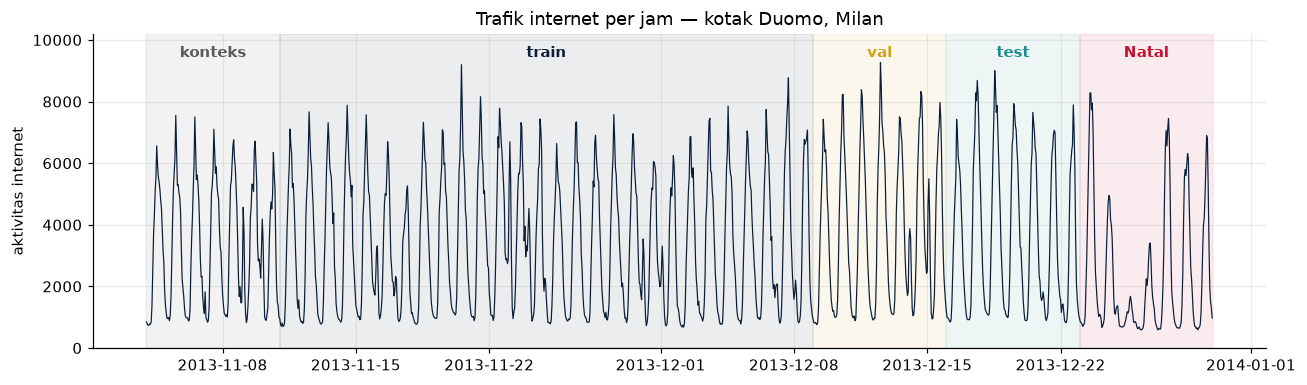

In [2]:
BATAS = pd.to_datetime(["2013-11-04", "2013-11-11", "2013-12-09", "2013-12-16", "2013-12-23", "2013-12-30"])
PERAN = [("konteks", GRAY), ("train", NAVY), ("val", GOLD), ("test", TEAL), ("Natal", RED)]

fig, ax = plt.subplots(figsize=(12, 3.6))
for (nama, warna), a, b in zip(PERAN, BATAS[:-1], BATAS[1:]):
    ax.axvspan(a, b, color=warna, alpha=0.08)
    ax.text(a + (b - a) / 2, df.net.max() * 1.02, nama, ha="center", color=warna, fontweight="bold")
ax.plot(df.index, df.net, color=NAVY, lw=0.8)
ax.set_ylabel("aktivitas internet")
ax.set_title("Trafik internet per jam — kotak Duomo, Milan")
ax.set_ylim(0, df.net.max() * 1.1)
plt.tight_layout()
plt.savefig(HASIL_DIR / "deret_waktu.png", dpi=200, bbox_inches="tight")
plt.show()

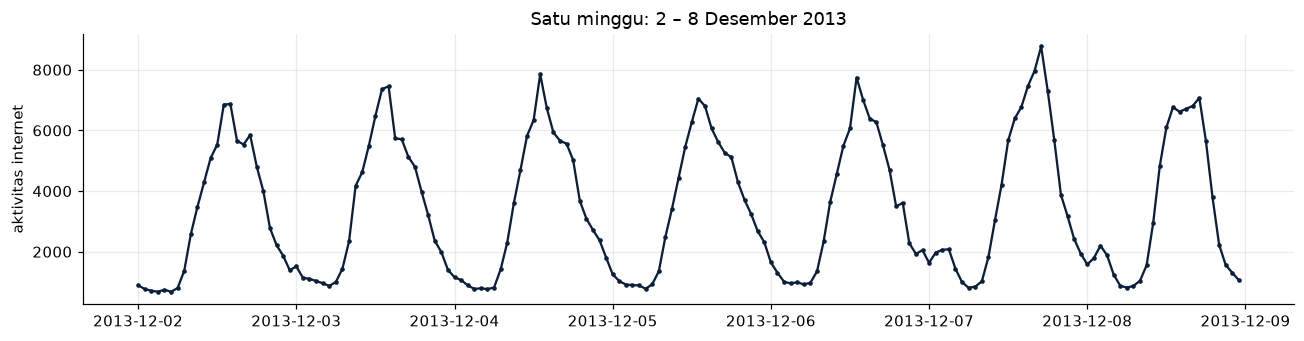

In [3]:
# Perbesar satu minggu (Senin–Minggu)
minggu = df.loc["2013-12-02":"2013-12-08"]
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(minggu.index, minggu.net, color=NAVY, lw=1.5, marker="o", ms=2)
ax.set_title("Satu minggu: 2 – 8 Desember 2013")
ax.set_ylabel("aktivitas internet")
plt.tight_layout()
plt.savefig(HASIL_DIR / "satu_minggu.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 2. Pola Harian & Mingguan

Rata-rata per jam memperlihatkan "denyut" kota: sepi menjelang subuh, naik di pagi hari, puncak di siang hingga sore.

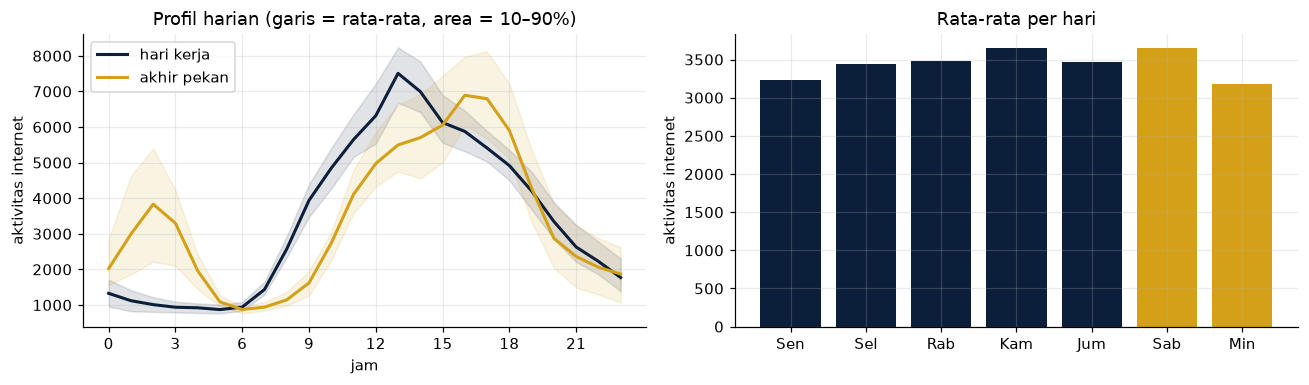

In [4]:
latih = df.loc[:"2013-12-15"]              # hanya data sebelum test, agar tidak "mengintip"
akhir_pekan = latih.index.dayofweek >= 5

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for mask, nama, warna in [(~akhir_pekan, "hari kerja", NAVY), (akhir_pekan, "akhir pekan", GOLD)]:
    profil = latih[mask].net.groupby(latih[mask].index.hour)
    axes[0].plot(profil.mean().index, profil.mean(), color=warna, lw=2, label=nama)
    axes[0].fill_between(profil.mean().index, profil.quantile(0.1), profil.quantile(0.9), color=warna, alpha=0.12)
axes[0].set_xlabel("jam"); axes[0].set_ylabel("aktivitas internet"); axes[0].set_xticks(range(0, 24, 3))
axes[0].set_title("Profil harian (garis = rata-rata, area = 10–90%)"); axes[0].legend()

hari = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
per_hari = latih.net.groupby(latih.index.dayofweek).mean()
axes[1].bar(hari, per_hari, color=[NAVY] * 5 + [GOLD] * 2)
axes[1].set_title("Rata-rata per hari"); axes[1].set_ylabel("aktivitas internet")
plt.tight_layout()
plt.savefig(HASIL_DIR / "pola_harian.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 3. Internet, Telepon, dan SMS

Ketiga layanan dipakai oleh orang yang sama di tempat yang sama, sehingga polanya mirip. Karena itu `call` dan `sms` kita pakai sebagai **fitur tambahan** untuk memprediksi `net`.

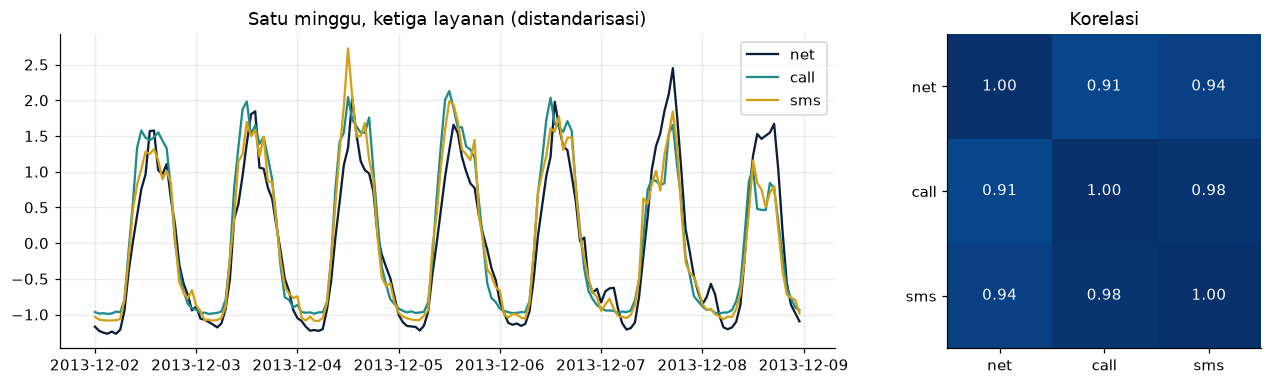

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
z = (minggu - latih.mean()) / latih.std()        # standarisasi agar skalanya sebanding
for kol, warna in [("net", NAVY), ("call", TEAL), ("sms", GOLD)]:
    axes[0].plot(z.index, z[kol], color=warna, lw=1.5, label=kol)
axes[0].set_title("Satu minggu, ketiga layanan (distandarisasi)"); axes[0].legend()

kor = latih.corr()
im = axes[1].imshow(kor, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(3), kor.columns); axes[1].set_yticks(range(3), kor.columns); axes[1].grid(False)
for a in range(3):
    for b in range(3):
        axes[1].text(b, a, f"{kor.iloc[a, b]:.2f}", ha="center", va="center", color="white" if kor.iloc[a, b] > 0.6 else NAVY)
axes[1].set_title("Korelasi")
plt.tight_layout()
plt.savefig(HASIL_DIR / "korelasi_layanan.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 4. Autokorelasi: Ingatan yang Dibutuhkan

Autokorelasi pada *lag* $k$ = korelasi antara trafik jam ini dan trafik $k$ jam sebelumnya. Puncak pada **24 jam** (kemarin, jam yang sama) dan **168 jam** (minggu lalu, jam yang sama) memberi petunjuk **berapa jauh ke belakang** model perlu "mengingat".

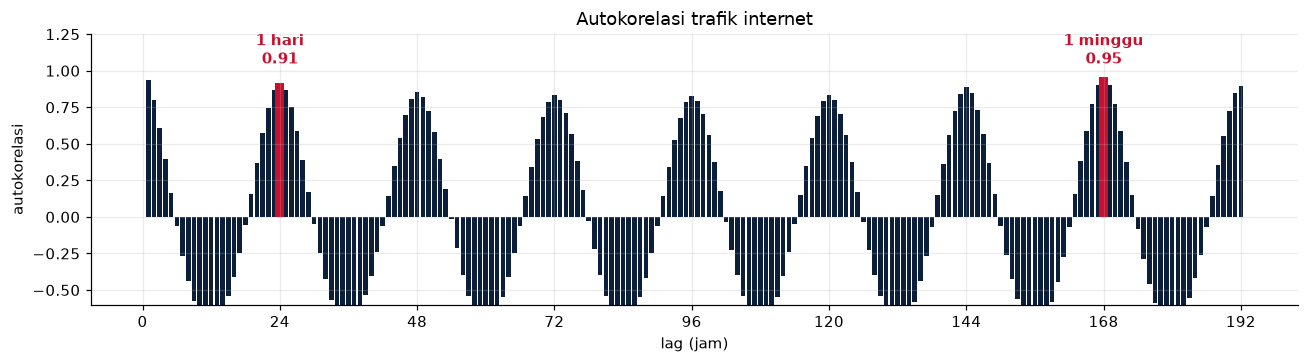

In [6]:
x = latih.net.values
lags = np.arange(1, 24 * 8 + 1)
acf = [np.corrcoef(x[:-k], x[k:])[0, 1] for k in lags]

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(lags, acf, color=NAVY, width=0.8)
for k, nama in [(24, "1 hari"), (168, "1 minggu")]:
    ax.bar(k, acf[k - 1], color=RED, width=1.6)
    ax.annotate(f"{nama}\n{acf[k - 1]:.2f}", (k, acf[k - 1]), xytext=(k, 1.05), ha="center", color=RED, fontweight="bold")
ax.set_xlabel("lag (jam)"); ax.set_ylabel("autokorelasi"); ax.set_ylim(-0.6, 1.25)
ax.set_xticks(range(0, 24 * 8 + 1, 24))
ax.set_title("Autokorelasi trafik internet")
plt.tight_layout()
plt.savefig(HASIL_DIR / "autokorelasi.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 5. Minggu Natal

Pada 24–26 Desember toko dan kantor tutup, sehingga pola trafik berubah drastis. Model yang hanya belajar dari minggu-minggu normal **belum pernah melihat** kejadian ini.

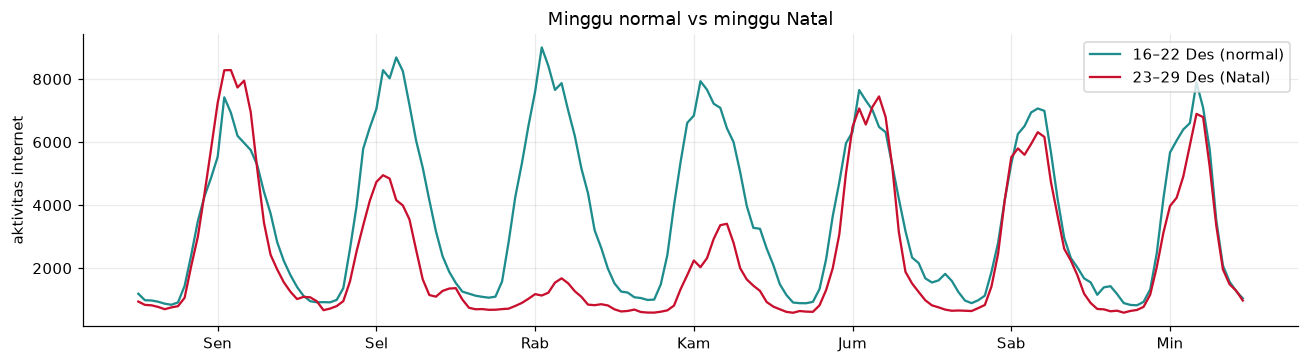

Penurunan rata-rata minggu Natal: 35%


In [7]:
fig, ax = plt.subplots(figsize=(12, 3.4))
normal = df.loc["2013-12-16":"2013-12-22"].net.values
natal = df.loc["2013-12-23":"2013-12-29"].net.values
jam = np.arange(168)
ax.plot(jam, normal, color=TEAL, lw=1.5, label="16–22 Des (normal)")
ax.plot(jam, natal, color=RED, lw=1.5, label="23–29 Des (Natal)")
ax.set_xticks(range(12, 168, 24), ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"])
ax.set_ylabel("aktivitas internet"); ax.legend()
ax.set_title("Minggu normal vs minggu Natal")
plt.tight_layout()
plt.savefig(HASIL_DIR / "minggu_natal.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Penurunan rata-rata minggu Natal: {(1 - natal.mean() / normal.mean()) * 100:.0f}%")

---
## Ringkasan

- Trafik punya **pola harian yang kuat** dan sedikit perbedaan hari kerja vs akhir pekan.
- `net`, `call`, `sms` saling berkorelasi, jadi berguna sebagai fitur.
- Autokorelasi tinggi di lag 24 dan 168 jam: model perlu "mengingat" setidaknya 1 hari, mungkin 1 minggu.
- Minggu Natal menyimpang jauh dari pola biasa, jadi akan menjadi uji yang berat untuk semua model.

Lanjut ke **`03_rnn_lstm_gru_vs_ann.ipynb`**.